In [1]:
import numpy as np
import librosa as lr
import scipy as sp
import polars as pl
import matplotlib.pyplot as plt

from filters import *

from IPython.display import HTML

In [2]:
y, sr = lr.load("../data/audio/s04.wav", sr=None)

In [3]:
def quad_interp(f, db, k):
    delta = f[1] - f[0]

    a, b, c = db[k - 1], db[k], db[k + 1]

    p = 0.5 * (a - c) / (a - 2 * b + c)

    return f[k] + p * delta, b - 0.25 * (a - c) * p

Text(0, 0.5, 'level [dB]')

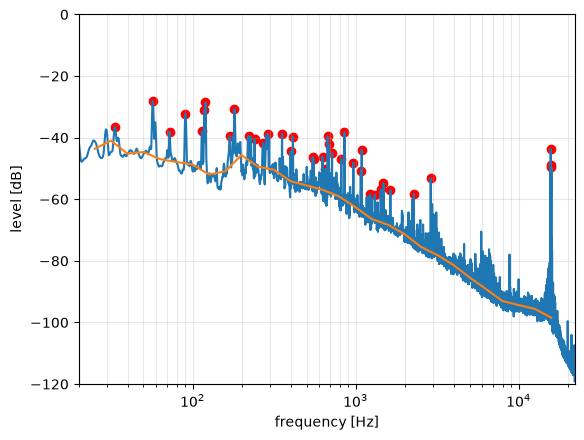

In [4]:
nperseg = 2**16

# spectrum and decibel conversion
f, P = sp.signal.welch(
    y, fs=sr, window="hann", nperseg=nperseg, scaling="spectrum", nfft=4 * nperseg
)
db = 10 * np.log10(2 * P + 1e-20)

# find peaks
peaks, _ = sp.signal.find_peaks(db, prominence=10, height=-60)
peak_freq, peak_db = quad_interp(f, db, peaks)
peak_width = sp.signal.peak_widths(P, peaks, rel_height=0.5)
peak_df = pl.DataFrame(
    {
        "idx": peaks,
        "peak_spec_freq": f[peaks],
        "peak_spec_db": db[peaks],
        "peak_spec_pow": P[peaks],
        "peak_freq": peak_freq,
        "peak_db": peak_db,
        "peak_spec_width": peak_width[0] * np.diff(f)[0] / (sr / nperseg),
    }
)

# fit the floor as medians across log-spaced bins
bin_centers = 1000 * 10 ** (np.arange(-16, 14) / 10)
bins = bin_centers / 10**0.05
floor = sp.stats.binned_statistic(f, db, statistic="median", bins=bins)[0]

# plot spectrum
plt.semilogx(f, db, label="spectrum")

# plot found peaks
plt.scatter(f[peaks], db[peaks], color="red")

# plot the "floor"
plt.semilogx(bin_centers[:-1], floor, label="floor")

plt.xlim(20, sr / 2)
plt.ylim(-120, 0)
plt.grid(True, which="both", alpha=0.3)
plt.xlabel("frequency [Hz]")
plt.ylabel("level [dB]")

now how do we fit the noise floor?

i see several "humps" and dips" together with two "straight lines" on the graph. this means we can fit a couple spectral tilt filters (pink-noise-ish) and peaking equalizer filters. So it's about translating the frequency response to scipy from faust implementation and optimizing parameters to match the curve.

Smith gives the following implementation of a peaking equalizer:
```
declare tf2s author "Julius O. Smith III";
declare tf2s copyright "Copyright (C) 2003-2019 by Julius O. Smith III <jos@ccrma.stanford.edu>";
declare tf2s license "MIT-style STK-4.3 license";
tf2s(b2,b1,b0,a1,a0,w1) = tf2(b0d,b1d,b2d,a1d,a2d)
with {
  c   = 1/tan(w1*0.5/ma.SR); // bilinear-transform scale-factor
  csq = c*c;
  d   = a0 + a1 * c + csq;
  b0d = (b0 + b1 * c + b2 * csq)/d;
  b1d = 2 * (b0 - b2 * csq)/d;
  b2d = (b0 - b1 * c + b2 * csq)/d;
  a1d = 2 * (a0 - csq)/d;
  a2d = (a0 - a1*c + csq)/d;
};


declare peak_eq author "Julius O. Smith III";
declare peak_eq copyright "Copyright (C) 2003-2019 by Julius O. Smith III <jos@ccrma.stanford.edu>";
declare peak_eq license "MIT-style STK-4.3 license";
peak_eq(Lfx,fx,B) = tf2s(1,b1s,1,a1s,1,wx) with {
  T = float(1.0/ma.SR);
  Bw = B*T/sin(wx*T); // prewarp s-bandwidth for more accuracy in z-plane
  a1 = ma.PI*Bw;
  b1 = g*a1;
  g = ba.db2linear(abs(Lfx));
  b1s = select2(Lfx>0,a1,b1); // When Lfx>0, pole dominates bandwidth
  a1s = select2(Lfx>0,b1,a1); // When Lfx<0, zero dominates
  wx = 2*ma.PI*fx;
};
```

Also, we will use bell SVFs in code. A Bell SVF filter is the same as peak_eq filter. In faust,
```
fi.svf.bell(f, Q, gain) = peak_eq(gain,f,B)
```
when `Q = sin(2*pi*f/sr) / (10**(gain/40)*pi*B/sr)` (by https://www.w3.org/TR/audio-eq-cookbook/#intro where `a1 = pi*Bw = 1/AQ` and `A=10**(gain/40)`)




In [5]:
# copied from .filters.py


def tf2s(b2, b1, b0, a1, a0, w1, sr=44_100):
    c = 1 / np.tan(w1 * 0.5 / sr)
    csq = c * c
    d = a0 + a1 * c + csq
    b0d = (b0 + b1 * c + b2 * csq) / d
    b1d = 2 * (b0 - b2 * csq) / d
    b2d = (b0 - b1 * c + b2 * csq) / d
    a1d = 2 * (a0 - csq) / d
    a2d = (a0 - a1 * c + csq) / d

    a = np.array([1, a1d, a2d])
    b = np.array([b0d, b1d, b2d])
    return b, a


def boost(gain, freq, B, sr=44_100):
    # decibel to linear
    g = 10 ** (np.abs(gain) / 20)

    T = 1.0 / sr
    wx = 2 * np.pi * freq
    Bw = B * T / np.sin(wx * T)
    a1 = np.pi * Bw
    b1 = g * a1
    if gain <= 0:
        a1s, b1s = b1, a1
    else:
        a1s, b1s = a1, b1
    return tf2s(1, b1s, 1, a1s, 1, wx, sr)


def bell(freq, Q, gain, sr=44_100):
    # abs: a cut and a boost of the same Q have the same width
    A = 10 ** (abs(gain) / 40)
    B = np.sin(2 * np.pi * freq / sr) / (A * np.pi * Q / sr)
    return boost(gain, freq, B, sr)

for spectral tils, Smith gives us
```
declare tf1s author "Julius O. Smith III";
declare tf1s copyright "Copyright (C) 2003-2019 by Julius O. Smith III <jos@ccrma.stanford.edu>";
declare tf1s license "MIT-style STK-4.3 license";
tf1s(b1,b0,a0,w1) = tf1(b0d,b1d,a1d)
with {
  c   = 1/tan(w1*0.5/ma.SR); // bilinear-transform scale-factor
  d   = a0 + c;
  b1d = (b0 - b1*c) / d;
  b0d = (b0 + b1*c) / d;
  a1d = (a0 - c) / d;
};

declare spectral_tilt author "Julius O. Smith III";
declare spectral_tilt copyright "Copyright (C) 2003-2019 by Julius O. Smith III <jos@ccrma.stanford.edu>";
declare spectral_tilt license "MIT-style STK-4.3 license";
spectral_tilt(N,f0,bw,alpha) = seq(i,N,sec(i)) with {
  sec(i) = g * tf1s(b1,b0,a0,1) with {
    g = a0/b0; // unity dc-gain scaling
    b1 = 1.0;
    b0 = mzh(i);
    a0 = mph(i);
    mzh(i) = prewarp(mz(i),ma.SR,w0); // prewarping for bilinear transform
    mph(i) = prewarp(mp(i),ma.SR,w0);
    prewarp(w,SR,wp) = wp * tan(w*T/2) / tan(wp*T/2) with { T = 1/ma.SR; };
    mz(i) = w0 * r ^ (-alpha+i); // minus zero i in s plane
    mp(i) = w0 * r ^ i; // minus pole i in s plane
    f0p = max(f0,ma.EPSILON); // cannot go to zero
    w0 = 2 * ma.PI * f0p; // radian frequency of first pole
    f1 = f0p + bw; // upper band limit
    r = (f1/f0p)^(1.0/float(N-1)); // pole ratio (2 => octave spacing)
  };
};
```
in Faust, where `N` is the order, `f0` is the lower frequency limit, `bw` - bandwidth, and `alpha` is the slope in "nepers per neper" (log-ratio of db over freq. In particular, `alpha=-0.5` is the pinking filter

In [6]:
# copied from filters.py


def tf1s(b1, b0, a0, w1, sr=44_100):
    c = 1 / np.tan(w1 * 0.5 / sr)
    d = a0 + c
    b1d = (b0 - b1 * c) / d
    b0d = (b0 + b1 * c) / d
    a1d = (a0 - c) / d
    return np.array([b0d, b1d]), np.array([1, a1d])


def spectral_tilt(N, f0, bw, alpha, sr=44_100):
    T, w0 = 1 / sr, 2 * np.pi * f0
    r = ((f0 + bw) / f0) ** (1 / (N - 1))

    prewarp = lambda w: w0 * np.tan(w * T / 2) / np.tan(w0 * T / 2)

    # build the second-order sections
    rows = []
    for i in range(N):
        b0 = prewarp(w0 * r ** (i - alpha))
        a0 = prewarp(w0 * r**i)

        g = a0 / b0

        [b0d, b1d], [a0d, a1d] = tf1s(1, b0, a0, 1, sr)

        rows.append((np.array([g * b0d, g * b1d, 0]), np.array([1, a1d, 0])))

    return np.array(rows)

Now we just combine all the second-order sections together and fit the curve

In [7]:
# copied from filters.py


def sos(*filters):
    return np.vstack([np.reshape(f, (-1, 6)) for f in filters])


def db_curve(sos_rows, freqs, sr=44_100):
    _, h = sp.signal.sosfreqz(sos_rows, worN=freqs, fs=sr)
    return 20 * np.log10(np.abs(h))

In [8]:
def filter_chain(lo_alpha, hi_alpha, knee, dent, dent_Q, bump, bump_Q, sr=44_100):
    return sos(
        # low-freq straight line starting at 12 and going for `knee` bandwidth
        spectral_tilt(4, 12, knee - 12, lo_alpha, sr),
        # medium-freq straight line starting at `knee` and going until 9000
        #  this one is too steep so split into two
        spectral_tilt(6, knee, 9000 - knee, hi_alpha / 2, sr),
        spectral_tilt(6, knee, 9000 - knee, hi_alpha / 2, sr),
        # dent at 140 Hz
        bell(140, dent_Q, dent, sr),
        # bump at 200 hz
        bell(200, bump_Q, bump, sr),
    )


def model(p, f, sr=44_100):
    *chain_params, chain_gain, wn_gain, lopass_freq = p
    # no.noise has a flat power in db/Hz
    wn = 10 * np.log10(2 / (3 * sr))
    # we sum two independent noise sources:
    #   white noise flat hiss and "shaped"/filtered noise floor
    body = wn + db_curve(filter_chain(*chain_params), f) + chain_gain
    hiss = wn + wn_gain
    # sum in logs
    total = 10 * np.log10(10 ** (body / 10) + 10 ** (hiss / 10))
    # fit a low-pass filter on top of the two at the end
    return total + db_curve(sp.signal.butter(4, lopass_freq, fs=sr, output="sos"), f)

In [9]:
# now re-load the file in stereo and fit each channel
y, sr = lr.load(
    "../data/audio/s04.wav", sr=None, mono=False
)

nperseg = 2**16
bin_centers = 1000 * 10 ** (np.arange(-16, 14) / 10)
bins = bin_centers / 10**0.05

# spectrum of both channels at once, shape (2, freqs)
f, P = sp.signal.welch(
    y, fs=sr, window="hann", nperseg=nperseg, scaling="spectrum", nfft=4 * nperseg
)
db = 10 * np.log10(2 * P + 1e-20)

# tones: need one peak freq but separate gains
found = [sp.signal.find_peaks(db[ch], prominence=10, height=-60)[0] for ch in range(2)]


# merge peaks closer than 8 points apart

# first sort and find all unique ones
thresh = 8
peaks = []
for k in np.sort(np.concatenate(found)):
    if not peaks or k - peaks[-1] > thresh:
        peaks.append(k)


# then get levels from each channel at the max
def tone_level(d, k):
    # channel max near the peak
    j = k - thresh + np.argmax(d[k - thresh : k + thresh + 1])
    # if we are at edge then peak missing :(,
    # read raw value for gain, omit freq
    if abs(j - k) == thresh:
        return np.nan, d[k]
    # interpolate as above
    return quad_interp(f, d, j)


tones = []
for k in peaks:
    freqs, gains = [], []
    for ch in range(2):
        # is there a peak found in the channel
        near = found[ch][np.abs(found[ch] - k) <= thresh]
        if len(near):
            # interpolate as above at loudest nearby point
            freq, gain = quad_interp(f, db[ch], near[np.argmax(db[ch][near])])
            freqs.append(freq)
        else:
            # peak missing in this channel :( read "peak" value for gain, omit freq
            gain = db[ch][k]
        gains.append(gain)

    tones.append({"freq": np.mean(freqs), "gainL": gains[0], "gainR": gains[1]})

# export the tones
pl.DataFrame(tones).write_csv("../data/room-04-tones.csv")

# for each channel (also need separate centers in case we get a nan)
floor_curves, floor_bin_centers = [], []

for i, chan in enumerate(["L", "R"]):
    # fit the floor as medians across log-spaced bins
    # recompute the spectrum as and median noise floor with welch from the source file
    #   but now as "density"
    f_d, P_d = sp.signal.welch(
        y[i], fs=sr, window="hann", nperseg=nperseg, scaling="density"
    )

    floor_density = sp.stats.binned_statistic(
        f_d, 10 * np.log10(P_d + 1e-30), statistic="median", bins=bins
    )[0]

    # save the curves
    ok = ~np.isnan(floor_density) & (bin_centers[:-1] <= 20_000)
    floor_curves.append(floor_density[ok])
    floor_bin_centers.append(bin_centers[:-1][ok])

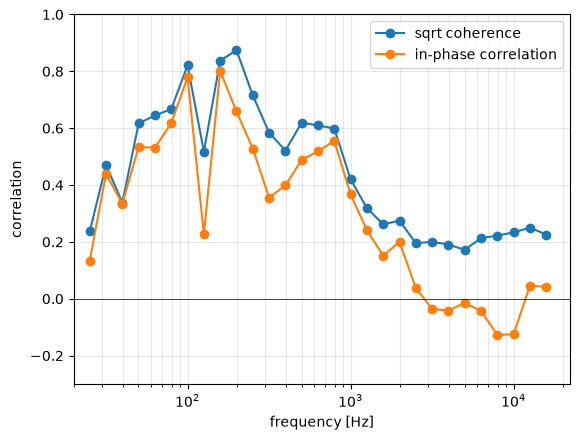

In [10]:
# ok so now we have saved the tones and got the overall noise curves. time to fit them to our filter model
# since we are in stereo, we have to look at how similar the two channels are

n = 2**16
# look at squared coherence
f_c, C = sp.signal.coherence(y[0], y[1], fs=sr, nperseg=n)
# and cross power spectral density to compute correlation
_, Pxy = sp.signal.csd(y[0], y[1], fs=sr, nperseg=n)
_, Pxx = sp.signal.welch(y[0], fs=sr, nperseg=n)
_, Pyy = sp.signal.welch(y[1], fs=sr, nperseg=n)

# bin it again
per_band = lambda v: sp.stats.binned_statistic(f_c, v, statistic="median", bins=bins)[0]
# this should give similarity at any phase
coh = per_band(C)
# and this should give similarity of phase (signed)
r = per_band(Pxy.real / np.sqrt(Pxx * Pyy))

plt.semilogx(bin_centers[:-1], np.sqrt(coh), "o-", label="sqrt coherence")
plt.semilogx(bin_centers[:-1], r, "o-", label="in-phase correlation")
plt.axhline(0, color="k", lw=0.5)
plt.ylim(-0.3, 1)
plt.xlim(20, sr / 2)
plt.grid(True, which="both", alpha=0.3)
plt.xlabel("frequency [Hz]")
plt.ylabel("correlation")
plt.legend()

RMS error 1.02 dB
True `ftol` termination condition is satisfied.

L channel fit:
lo_alpha     -0.459
hi_alpha     -1.570
knee        969.444
dent         -7.636
dent_Q        1.500
bump          7.412
bump_Q        1.500
chain_gain     8.741
wn_gain     -51.588
lopass_freq 16315.676
chain gain          2.736  (8.7 dB)
hiss gain           0.003  (-51.6 dB)

R channel fit:
lo_alpha     -0.445
hi_alpha     -1.570
knee        969.444
dent         -3.215
dent_Q        1.500
bump          4.610
bump_Q        1.500
chain_gain     8.506
wn_gain     -50.732
lopass_freq 16315.676
chain gain          2.662  (8.5 dB)
hiss gain           0.003  (-50.7 dB)



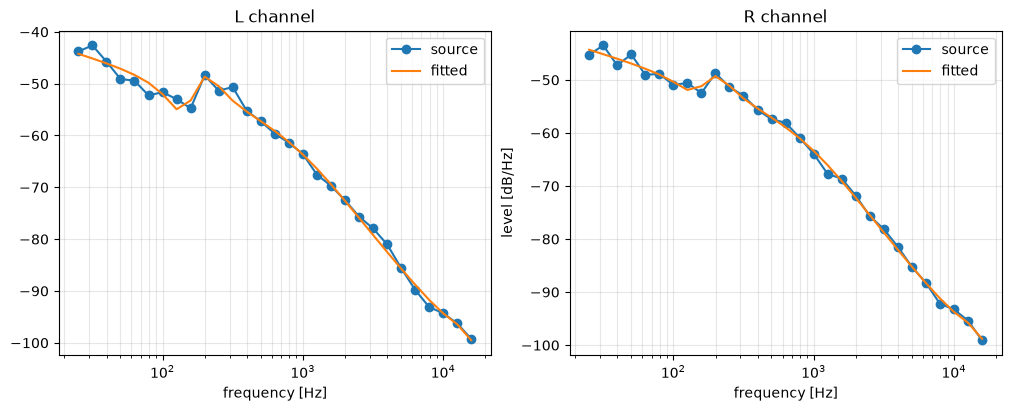

In [11]:
# time to fit the parameters of the filter model to the file
# from the plot we see can approximate the picture to assume
# that in low frequencies the channels are correlated ar r = 0.75 below 200,
# 0.45 up to 1400, and above they are independent

# this means two things: we should correlate the noises at low frequencies in Faust,
# and in optimizing the parameters per channel we can share some parameters but
# split the others (in the filter model)

# sensible optimization bounds for parameters
#          lo     hi     knee  dent dent_Q bump bump_Q chain_gain wn_gain lopass_freq
x0 = [-0.5, -1.53, 1000, -4, 2, 6, 2.5, 8, -40, 17000]
lower = [-0.99, -1.98, 150, -15, 1.5, 0, 1.5, -40, -80, 10000]
upper = [0, 0, 3000, 0, 20, 15, 20, 60, 0, 21000]

# any parameter of the room should be the shared
# but low-frequency params should be different per channel:

# hi_alpha, knee (Hz), bell Q's, lopass_freq
shared = [1, 2, 4, 6, 9]
# lo_alha, dent/bump dBs, gains
per_channel = [0, 3, 5, 7, 8]

# for optimization, we pack all parameters together: shared, Ls, Rs


# packing initial values and bounds
def pack(v):
    return np.concatenate(
        [np.array(v)[shared], np.array(v)[per_channel], np.array(v)[per_channel]]
    )


# unpacking per channel
def channel_params(q, ch):
    p = np.empty(10)
    p[shared] = q[:5]
    p[per_channel] = q[5 + 5 * ch : 10 + 5 * ch]
    return p


def objective(q, targets, freqs):
    return np.concatenate(
        [model(channel_params(q, ch), freqs[ch]) - targets[ch] for ch in range(2)]
    )


fit = sp.optimize.least_squares(
    objective,
    pack(x0),
    bounds=(pack(lower), pack(upper)),
    x_scale="jac",
    args=(floor_curves, floor_bin_centers),
)

print(f"RMS error {np.sqrt(np.mean(fit.fun**2)):.2f} dB")
print(fit.success, fit.message)
print()

fitted_params = []
fig, axs = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")

for i, chan in enumerate(["L", "R"]):
    x_chan = channel_params(fit.x, i)
    fitted_params.append(x_chan)
    print(f"{chan} channel fit:")
    for name, value in zip(
        [
            "lo_alpha",
            "hi_alpha",
            "knee",
            "dent",
            "dent_Q",
            "bump",
            "bump_Q",
            "chain_gain",
            "wn_gain",
            "lopass_freq",
        ],
        x_chan,
    ):
        print(f"{name:9} {value:9.3f}")
    print(f"chain gain      {10 ** (x_chan[-3] / 20):9.3f}  ({x_chan[-3]:.1f} dB)")
    print(f"hiss gain       {10 ** (x_chan[-2] / 20):9.3f}  ({x_chan[-2]:.1f} dB)")

    print()

    # plot to check
    ax = axs[i]
    ax.semilogx(floor_bin_centers[i], floor_curves[i], "o-", label="source")
    ax.semilogx(
        floor_bin_centers[i], model(x_chan, floor_bin_centers[i]), label="fitted"
    )
    ax.grid(True, which="both", alpha=0.3)
    ax.set_xlabel("frequency [Hz]")
    ax.set_ylabel("level [dB/Hz]")
    ax.legend()
    ax.set_title(f"{chan} channel")

# save everything to a csv
names = [
    "loAlpha",
    "hiAlpha",
    "knee",
    "dent",
    "dentQ",
    "bump",
    "bumpQ",
    "chainGain",
    "wnGain",
    "lopassFreq",
]
pl.DataFrame([dict(zip(names, fitted_params[ch])) for ch in range(2)]).write_csv(
    "../data/room-04-fit.csv"
)

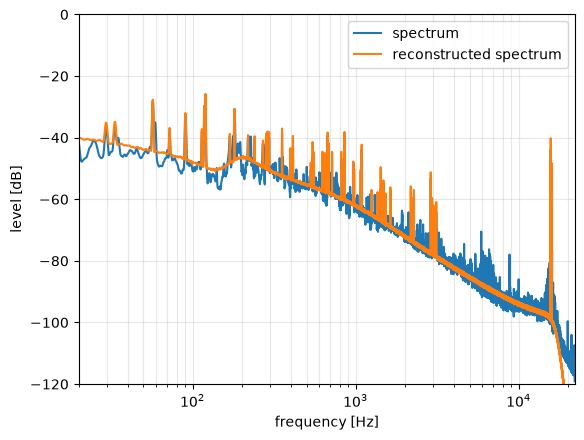

In [12]:
# now render and compare!!
nperseg = 2**16

y, sr = lr.load("../data/audio/s04.wav", sr=None)

# spectrum and decibel conversion
f, P = sp.signal.welch(
    y, fs=sr, window="hann", nperseg=nperseg, scaling="spectrum", nfft=4 * nperseg
)
db = 10 * np.log10(2 * P + 1e-20)

# plot spectrum
plt.semilogx(f, db, label="spectrum")

# load and plot the faust version
y_fau, sr_fau = lr.load("../build/room-04.wav", sr=None)
f_fau, P_fau = sp.signal.welch(
    y_fau,
    fs=sr_fau,
    window="hann",
    nperseg=nperseg,
    scaling="spectrum",
    nfft=4 * nperseg,
)
db_fau = 10 * np.log10(2 * P_fau + 1e-20)

plt.semilogx(f_fau, db_fau, label="reconstructed spectrum")

plt.xlim(20, sr / 2)
plt.ylim(-120, 0)
plt.grid(True, which="both", alpha=0.3)
plt.xlabel("frequency [Hz]")
plt.ylabel("level [dB]")
plt.legend()